In [32]:

from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
from langchain_core.tools import tool
from langchain_core.messages import AIMessage, HumanMessage, ToolMessage, SystemMessage
import os


load_dotenv()

if os.environ['OPENAI_API_KEY']:
    print("Openai key is set")
else:
    raise ValueError("openAi key is not set")


llm_openai = ChatOpenAI(model='gpt-5-mini',temperature=0)



Openai key is set


In [33]:
from pydantic import BaseModel, Field
from typing import Literal, TypedDict
class llm_schema (BaseModel) :
    funny_flag : Literal['funny','not funny'] = Field(description="Whether the joke is funny or not")
    feedback : str  = Field(description="Feedback on the joke")


llm_openai_schema = llm_openai.with_structured_output(llm_schema)




In [34]:
class graph_schema(TypedDict):
    topic:str
    feedback:str
    funny_flag:str
    joke:str
    max_iterations: int

In [35]:

def genrate_node(state:graph_schema)-> graph_schema:
    topic =  state['topic']
    if state['feedback']:
        response = llm_openai.invoke(f"Please modify the following joke {state['joke']} based on the following feedback: {state['feedback']}")
    else: 
        response = llm_openai.invoke("Create only one joke about the following topic: " + topic)

    state['joke']= response.content
    return state




In [36]:
from langchain_core.prompts import ChatPromptTemplate
def evaluate_node(state:graph_schema)-> graph_schema:
    joke =state['joke']
    my_promot= ChatPromptTemplate.from_messages(
        [
            ('system','You are a comedy critic. Your job is to evaluate the following joke and provide feedback on how to make it funnier.'),
            ('user',f"Evaluate the following joke: {joke}\nRespond with 'funny' or 'not_funny' and provide feedback if it's not funny.")
        ]
    )
    chain = my_promot | llm_openai_schema

    response = chain.invoke({'joke':joke})
    state['max_iterations']= state['max_iterations']+1
    state['feedback']= response.feedback
    state['funny_flag']= response.funny_flag

    return state


In [37]:
## Condition 

def conditon(state:graph_schema)-> str:
    itr = state['max_iterations']
    if itr <=5 and state['funny_flag']!= 'funny':
        return 'evl'
    else:
        return 'end'
    

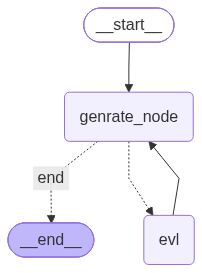

In [38]:
from langgraph.graph import StateGraph, START, END

graph = StateGraph(graph_schema)

graph.add_node('evl',evaluate_node)
graph.add_node('genrate_node',genrate_node)


graph.add_edge(START, 'genrate_node')
graph.add_conditional_edges('genrate_node',conditon,{
    'evl':'evl',
    'end':END
})

graph.add_edge('evl','genrate_node')
graph.add_edge('genrate_node',END)


final = graph.compile()
from IPython.display import Image, display
Image(final.get_graph().draw_mermaid_png())


In [39]:
for chunk in final.stream(
    {
        "topic": "Cars",
        "joke": "",
        "funny_flag": "",
        "feedback": "",
        "max_iterations": 0
    },
    stream_mode="updates"
):
    print(chunk)

{'genrate_node': {'topic': 'Cars', 'feedback': '', 'funny_flag': '', 'joke': "I wanted to buy a hybrid car, but I couldn't decide — do I want something fuel-efficient or just good at giving mixed signals?", 'max_iterations': 0}}
{'evl': {'topic': 'Cars', 'feedback': 'Solid, clever one-liner — the double-meaning of “hybrid” as fuel-efficient and emotionally ambiguous lands. To make it funnier: tighten the setup (shorter → quicker payoff), exaggerate the contrast for more surprise, and emphasize delivery (a beat before the punch). Example rewrites: "I wanted a hybrid — couldn\'t decide: fuel-efficient or just great at giving mixed signals?" or "I was shopping hybrids. Tough call: save gas or keep my dating life honest?" Delivery tip: pause after the setup word (hybrid/decide) so the audience has a beat to expect a car joke, then drop the emotional twist.', 'funny_flag': 'funny', 'joke': "I wanted to buy a hybrid car, but I couldn't decide — do I want something fuel-efficient or just good